# 01 Error analysis: false alerts and missed rises

**Data: FAKE predictions.** The code is real; the numbers mean nothing until the real files arrive.

Every forecast lands in one of four boxes:

| | Actually rose | Didn't rise |
| --- | --- | --- |
| **Model said rising** | Correct alert | False alert (wasted stock) |
| **Model said not rising** | Missed rise (lost sales) | Correct quiet |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from common import load_predictions, RISING_THRESHOLD

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

df = load_predictions()

# Put every forecast in one of the four boxes.
said_rising = df["predicted_growth"] > RISING_THRESHOLD
rose = df["actual_growth"] > RISING_THRESHOLD
df["outcome"] = "Correct quiet"
df.loc[said_rising & rose, "outcome"] = "Correct alert"
df.loc[said_rising & ~rose, "outcome"] = "False alert"
df.loc[~said_rising & rose, "outcome"] = "Missed rise"

# The main model and horizon for the detailed questions below.
MODEL, HORIZON = "lightgbm", 4
main = df[(df["model"] == MODEL) & (df["horizon"] == HORIZON)].copy()
print(f"{len(main):,} forecasts for {MODEL}, {HORIZON} weeks ahead")

4,895 forecasts for lightgbm, 4 weeks ahead


## 1. The four boxes for the main model

Counts and shares of all forecasts.

In [2]:
boxes = main["outcome"].value_counts().reindex(["Correct alert", "False alert", "Missed rise", "Correct quiet"])
pd.DataFrame({"forecasts": boxes, "share (%)": (100 * boxes / boxes.sum()).round(1)})

,forecasts,share (%)
outcome,,
Correct alert,702,14.3
False alert,303,6.2
Missed rise,241,4.9
Correct quiet,3649,74.5


## 2. Precision and recall for every model

- **Precision** = correct alerts ÷ all alerts. How often an alert is right.
- **Recall** = correct alerts ÷ all real rises. How many real rises were caught.

A model that never says "rising" (like the 4-week average) has no precision: it makes no alerts at all.

In [3]:
def alert_scores(group):
    counts = group["outcome"].value_counts()
    correct = counts.get("Correct alert", 0)
    false = counts.get("False alert", 0)
    missed = counts.get("Missed rise", 0)
    alerts = correct + false
    return pd.Series({
        "alerts": alerts,
        "false alerts": false,
        "missed rises": missed,
        "precision (%)": round(100 * correct / alerts, 1) if alerts else None,
        "recall (%)": round(100 * correct / (correct + missed), 1),
    })

scores = df.groupby(["horizon", "model"])[["outcome"]].apply(alert_scores)
counts = ["alerts", "false alerts", "missed rises"]
scores[counts] = scores[counts].astype(int)
scores

alerts  false alerts  missed rises  precision (%)  \
horizon model                                                               
4       four_week_avg        0             0           943            NaN   
        last_value         623           310           630           50.2   
        lightgbm          1005           303           241           69.9   
        seasonal_naive     597           389           735           34.8   
8       four_week_avg        0             0          1323            NaN   
        last_value         605           364          1082           39.8   
        lightgbm          1258           380           445           69.8   
        seasonal_naive     921           489           891           46.9   

                        recall (%)  
horizon model                       
4       four_week_avg          0.0  
        last_value            33.2  
        lightgbm              74.4  
        seasonal_naive        22.1  
8       four_week_avg          0.0  
        last_value            18.2  
        lightgbm              66.4  
        seasonal_naive        32.7

## 3. When do false alerts happen?

Share of forecasts that were false alerts, per month the forecast was made. The shaded area is the spring 2026 spike period (March–May).

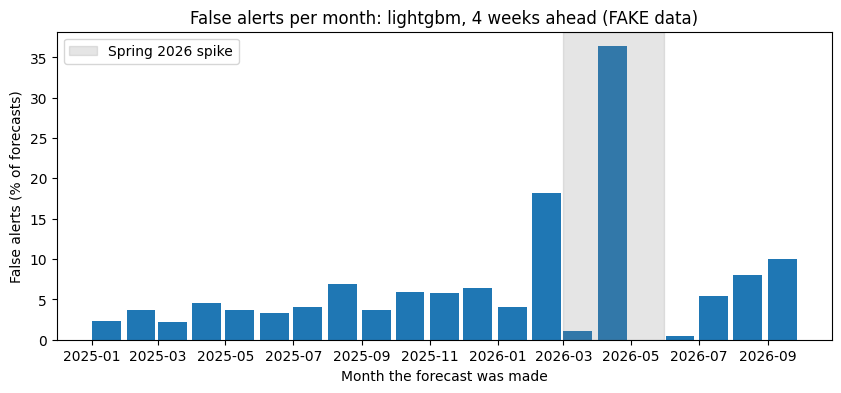

In [4]:
main["month"] = main["origin"].dt.to_period("M").dt.to_timestamp()
monthly = main.groupby("month")["outcome"].apply(lambda s: 100 * (s == "False alert").mean())

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(monthly.index, monthly.values, width=26, align="edge")  # each bar fills its month
ax.axvspan(pd.Timestamp("2026-03-01"), pd.Timestamp("2026-05-31"), color="grey", alpha=0.2, label="Spring 2026 spike")
ax.set_title(f"False alerts per month: {MODEL}, {HORIZON} weeks ahead (FAKE data)")
ax.set_xlabel("Month the forecast was made")
ax.set_ylabel("False alerts (% of forecasts)")
ax.legend()
fig.savefig(FIGURES / "01_false_alerts_by_month.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Why: does the model chase recent jumps?

**Recent jump** = last 4-week average ÷ the 4-week average one month earlier. Above 1 means the style has just gone up.

If false alerts have much bigger recent jumps than correct alerts, the model is mistaking short bursts for lasting trends.

In [5]:
main = main.sort_values(["item", "origin"])
main["recent_jump"] = main["last4_avg"] / main.groupby("item")["last4_avg"].shift(4)

jumps = (main.dropna(subset=["recent_jump"])
             .groupby("outcome")["recent_jump"]
             .median()
             .round(2)
             .reindex(["Correct alert", "False alert", "Missed rise", "Correct quiet"]))
pd.DataFrame({"median recent jump": jumps})

,median recent jump
outcome,
Correct alert,1.07
False alert,1.15
Missed rise,0.96
Correct quiet,0.99


## 5. Where: mistakes by category

Share of forecasts in each category that were false alerts or missed rises, sorted by false alerts.

In [6]:
by_category = (main.groupby("category")["outcome"]
                   .value_counts(normalize=True)
                   .unstack(fill_value=0)
                   .mul(100)
                   .round(1))
by_category[["False alert", "Missed rise"]].sort_values("False alert", ascending=False)

outcome,False alert,Missed rise
category,,
Aesthetics and styles,9.0,7.2
Trousers and shorts,7.9,4.3
Bags,7.2,4.5
Tops and knitwear,7.0,6.7
Skirts and dresses,7.0,4.5
Jeans and denim,6.1,3.8
Patterns and materials,5.6,4.5
Shoes,5.2,3.6
Accessories,4.7,2.7


## 6. Which styles are missed most often?

Styles with the most missed rises. New styles with little history are the usual suspects.

In [7]:
missed = main[main["outcome"] == "Missed rise"]["item"].value_counts().head(10)
pd.DataFrame({"missed rises": missed})

,missed rises
item,
balletcore,11
belt bag,11
bomber jacket,11
cardigan,11
gorpcore,11
blazer,9
satin,7
leggings,7
crop top,7


## What this shows (will be shown once real results are in)

One or two sentences per question, each with its number:

1. Precision and recall of the best model vs. the baselines:
2. When false alerts happen:
3. Why (recent jumps):
4. Where (categories, styles):